# Deteksi Deforestasi Hutan Tropis di Sumatra

## Latar Belakang
Hutan tropis memiliki peran penting dalam menyimpan karbon, menjaga keanekaragaman hayati, mengatur siklus air, dan menyediakan habitat bagi flora serta fauna. Perubahan tutupan hutan dapat terjadi akibat aktivitas manusia maupun faktor alam. Oleh karena itu, analisis data dan citra satelit dapat dimanfaatkan untuk membantu memantau perubahan tutupan hutan secara berkala.

## Tujuan
1. Mengidentifikasi tren kehilangan tutupan pohon di wilayah Sumatra.
2. Membandingkan kehilangan tutupan pohon antarperiode.
3. Menyajikan hasil analisis melalui tabel dan visualisasi.
4. Menentukan wilayah atau periode yang perlu ditinjau lebih lanjut.
5. Menyiapkan dasar untuk pengembangan klasifikasi citra satelit menggunakan AI.

## Pertanyaan Analisis
- Bagaimana tren kehilangan tutupan pohon dari tahun ke tahun?
- Pada tahun berapa kehilangan tutupan pohon paling tinggi?
- Wilayah mana yang perlu diprioritaskan untuk pemeriksaan lanjutan?

## Batasan
Tahap awal menggunakan data kehilangan tutupan pohon yang tersedia dari sumber data terbuka. Kehilangan tutupan pohon tidak selalu berarti deforestasi permanen, sehingga interpretasi harus mempertimbangkan kondisi lahan dan konteks setempat. Hasil analisis awal bukan bukti otomatis terjadinya pelanggaran atau penyebab kehilangan hutan.

In [1]:

import os

# Membuat folder proyek
os.makedirs("data", exist_ok=True)
os.makedirs("outputs", exist_ok=True)

print("Folder proyek berhasil disiapkan.")
print("Struktur folder:")
print("- data/")
print("- outputs/")


Folder proyek berhasil disiapkan.
Struktur folder:
- data/
- outputs/


In [2]:

import pandas as pd
import os

# Memeriksa file Excel yang tersedia di Colab
print(os.listdir("/content"))


['.config', 'data', 'outputs', 'sample_data']


In [3]:

import pandas as pd
import os

# Memastikan file Excel tersedia
file_path = "/content/IDN.xlsx"

if not os.path.exists(file_path):
    from google.colab import files
    uploaded = files.upload()
    file_path = "/content/" + next(iter(uploaded))

# Membaca data kehilangan tutupan pohon tingkat provinsi
df = pd.read_excel(
    file_path,
    sheet_name="Subnational 1 tree cover loss"
)

# Menampilkan nama kolom dan beberapa data awal
print("Ukuran dataset:", df.shape)
print("\nNama kolom:")
print(df.columns.tolist())

print("\nContoh data:")
display(df.head())


Saving IDN.xlsx to IDN.xlsx
Ukuran dataset: (272, 31)

Nama kolom:
['country', 'subnational1', 'threshold', 'area_ha', 'extent_2000_ha', 'extent_2010_ha', 'tc_loss_ha_2001', 'tc_loss_ha_2002', 'tc_loss_ha_2003', 'tc_loss_ha_2004', 'tc_loss_ha_2005', 'tc_loss_ha_2006', 'tc_loss_ha_2007', 'tc_loss_ha_2008', 'tc_loss_ha_2009', 'tc_loss_ha_2010', 'tc_loss_ha_2011', 'tc_loss_ha_2012', 'tc_loss_ha_2013', 'tc_loss_ha_2014', 'tc_loss_ha_2015', 'tc_loss_ha_2016', 'tc_loss_ha_2017', 'tc_loss_ha_2018', 'tc_loss_ha_2019', 'tc_loss_ha_2020', 'tc_loss_ha_2021', 'tc_loss_ha_2022', 'tc_loss_ha_2023', 'tc_loss_ha_2024', 'tc_loss_ha_2025']

Contoh data:


,country,subnational1,threshold,area_ha,extent_2000_ha,extent_2010_ha,tc_loss_ha_2001,tc_loss_ha_2002,tc_loss_ha_2003,tc_loss_ha_2004,...,tc_loss_ha_2016,tc_loss_ha_2017,tc_loss_ha_2018,tc_loss_ha_2019,tc_loss_ha_2020,tc_loss_ha_2021,tc_loss_ha_2022,tc_loss_ha_2023,tc_loss_ha_2024,tc_loss_ha_2025
0,Indonesia,Aceh,0,5683649,5683649,5683649,18401,11038,11858,19314,...,54064,49774,50239,31053,33716,34795,32777,43810,52496,67292
1,Indonesia,Aceh,10,5683649,5090906,4996298,18324,10988,11831,19213,...,50991,46782,47055,29148,31009,32516,30495,40109,47497,61830
2,Indonesia,Aceh,15,5683649,5050168,4946854,18309,10973,11827,19186,...,50712,46489,46774,28961,30750,32293,30263,39753,47042,61289
3,Indonesia,Aceh,20,5683649,5029128,4932161,18296,10965,11822,19167,...,50498,46263,46545,28829,30573,32117,30096,39485,46720,60899
4,Indonesia,Aceh,25,5683649,5014671,4908701,18290,10961,11819,19155,...,50374,46141,46416,28757,30474,32020,30014,39341,46529,60676


In [4]:

# Memilih data Provinsi Bengkulu
# Threshold 30% digunakan secara konsisten
bengkulu = df[
    (df["subnational1"].str.contains("Bengkulu", case=False, na=False))
    & (df["threshold"] == 30)
].copy()

# Menampilkan data yang berhasil ditemukan
display(bengkulu)

if bengkulu.empty:
    print("Data Bengkulu tidak ditemukan. Periksa nama provinsi dan threshold.")
else:
    print("\nData Bengkulu berhasil ditemukan!")


,country,subnational1,threshold,area_ha,extent_2000_ha,extent_2010_ha,tc_loss_ha_2001,tc_loss_ha_2002,tc_loss_ha_2003,tc_loss_ha_2004,...,tc_loss_ha_2016,tc_loss_ha_2017,tc_loss_ha_2018,tc_loss_ha_2019,tc_loss_ha_2020,tc_loss_ha_2021,tc_loss_ha_2022,tc_loss_ha_2023,tc_loss_ha_2024,tc_loss_ha_2025
37,Indonesia,Bengkulu,30,1981482,1795201,1788504,14198,10422,8104,25985,...,24378,27233,24625,18201,16310,14326,23799,29913,20997,27160



Data Bengkulu berhasil ditemukan!


In [5]:

import pandas as pd
import matplotlib.pyplot as plt

# Ambil data Provinsi Bengkulu dengan threshold 30%
baris_bengkulu = df[
    (df["subnational1"].str.contains("Bengkulu", case=False, na=False))
    & (df["threshold"] == 30)
]

if baris_bengkulu.empty:
    print("Data Bengkulu tidak ditemukan. Periksa kembali dataset.")
else:
    # Mengambil satu baris data Bengkulu
    data_bengkulu = baris_bengkulu.iloc[0]

    # Mengubah data tahunan menjadi tabel
    tahun = list(range(2001, 2026))
    kolom_tahun = [f"tc_loss_ha_{t}" for t in tahun]

    tabel_bengkulu = pd.DataFrame({
        "Tahun": tahun,
        "Kehilangan_Tutupan_Pohon_ha": [
            data_bengkulu[kolom] for kolom in kolom_tahun
        ]
    })

    # Tampilkan tabel
    display(tabel_bengkulu)

    print("Jumlah tahun yang dianalisis:", len(tabel_bengkulu))
    print(
        "Total kehilangan tutupan pohon 2001–2025:",
        f"{tabel_bengkulu['Kehilangan_Tutupan_Pohon_ha'].sum():,.0f}",
        "hektare"
    )


,Tahun,Kehilangan_Tutupan_Pohon_ha
0,2001,14198
1,2002,10422
2,2003,8104
3,2004,25985
4,2005,13141
5,2006,23588
6,2007,17580
7,2008,22353
8,2009,18756
9,2010,16013


Jumlah tahun yang dianalisis: 25
Total kehilangan tutupan pohon 2001–2025: 504,076 hektare


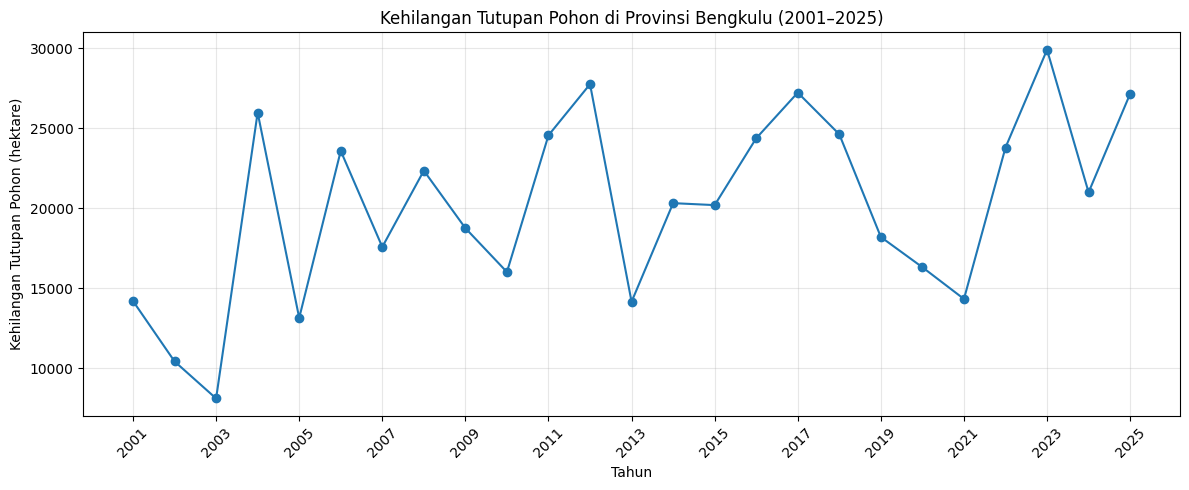

In [6]:

plt.figure(figsize=(12, 5))

plt.plot(
    tabel_bengkulu["Tahun"],
    tabel_bengkulu["Kehilangan_Tutupan_Pohon_ha"],
    marker="o"
)

plt.title("Kehilangan Tutupan Pohon di Provinsi Bengkulu (2001–2025)")
plt.xlabel("Tahun")
plt.ylabel("Kehilangan Tutupan Pohon (hektare)")
plt.xticks(range(2001, 2026, 2), rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()

# Simpan grafik ke folder outputs
plt.savefig("outputs/grafik_kehilangan_tutupan_pohon_bengkulu.png", dpi=300)

plt.show()


In [7]:

# Statistik kehilangan tutupan pohon Bengkulu, 2001–2025

kolom = "Kehilangan_Tutupan_Pohon_ha"

# Pastikan nilai dibaca sebagai angka
tabel_bengkulu[kolom] = pd.to_numeric(
    tabel_bengkulu[kolom], errors="coerce"
)

data_valid = tabel_bengkulu.dropna(subset=[kolom])

# Tahun dengan nilai tertinggi dan terendah
tertinggi = data_valid.loc[data_valid[kolom].idxmax()]
terendah = data_valid.loc[data_valid[kolom].idxmin()]

print("HASIL ANALISIS BENGKULU (2001–2025)")
print("-" * 40)
print(
    f"Tertinggi : {int(tertinggi['Tahun'])} — "
    f"{tertinggi[kolom]:,.0f} hektare"
)
print(
    f"Terendah  : {int(terendah['Tahun'])} — "
    f"{terendah[kolom]:,.0f} hektare"
)
print(f"Rata-rata : {data_valid[kolom].mean():,.2f} hektare/tahun")
print(f"Total     : {data_valid[kolom].sum():,.0f} hektare")
print(f"Jumlah data tahunan: {len(data_valid)} tahun")


HASIL ANALISIS BENGKULU (2001–2025)
----------------------------------------
Tertinggi : 2023 — 29,913 hektare
Terendah  : 2003 — 8,104 hektare
Rata-rata : 20,163.04 hektare/tahun
Total     : 504,076 hektare
Jumlah data tahunan: 25 tahun


In [8]:

# Simpan tabel tahunan sebagai CSV
tabel_bengkulu.to_csv(
    "outputs/data_kehilangan_tutupan_pohon_bengkulu.csv",
    index=False
)

print("Tabel berhasil disimpan!")
print("Lokasi: outputs/data_kehilangan_tutupan_pohon_bengkulu.csv")


Tabel berhasil disimpan!
Lokasi: outputs/data_kehilangan_tutupan_pohon_bengkulu.csv


In [9]:

# Menghitung perubahan tahunan
tabel_bengkulu["Perubahan_ha"] = (
    tabel_bengkulu["Kehilangan_Tutupan_Pohon_ha"].diff()
)

tabel_bengkulu["Perubahan_persen"] = (
    tabel_bengkulu["Kehilangan_Tutupan_Pohon_ha"]
    .pct_change() * 100
)

# Menampilkan hasil dari tahun 2002 sampai 2025
display(
    tabel_bengkulu[
        ["Tahun", "Kehilangan_Tutupan_Pohon_ha",
         "Perubahan_ha", "Perubahan_persen"]
    ].round(2)
)


,Tahun,Kehilangan_Tutupan_Pohon_ha,Perubahan_ha,Perubahan_persen
0,2001,14198,NaN,NaN
1,2002,10422,-3776.0,-26.60
2,2003,8104,-2318.0,-22.24
3,2004,25985,17881.0,220.64
4,2005,13141,-12844.0,-49.43
5,2006,23588,10447.0,79.50
6,2007,17580,-6008.0,-25.47
7,2008,22353,4773.0,27.15
8,2009,18756,-3597.0,-16.09
9,2010,16013,-2743.0,-14.62


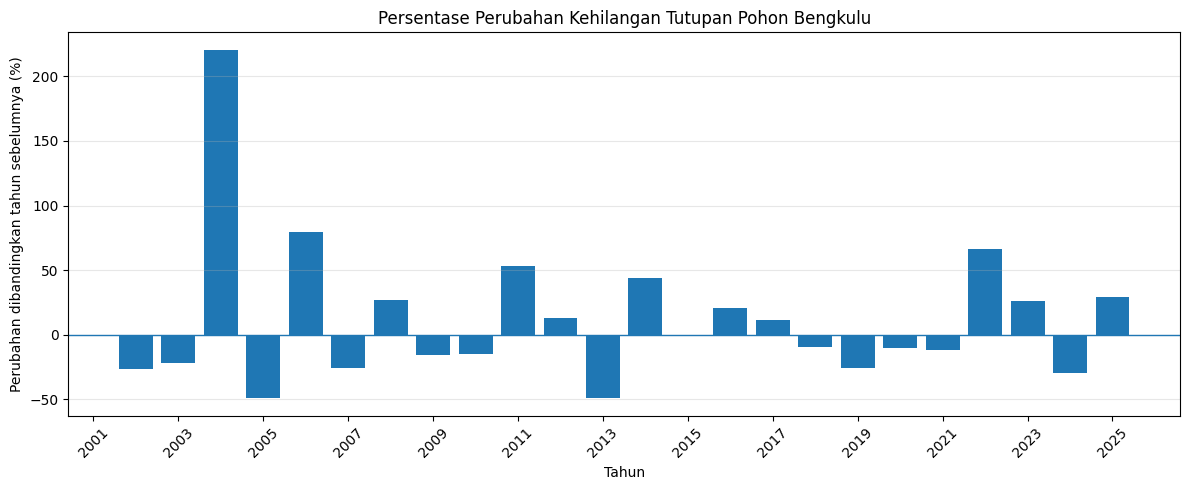

In [10]:

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.bar(
    tabel_bengkulu["Tahun"],
    tabel_bengkulu["Perubahan_persen"]
)

plt.axhline(y=0, linewidth=1)
plt.title("Persentase Perubahan Kehilangan Tutupan Pohon Bengkulu")
plt.xlabel("Tahun")
plt.ylabel("Perubahan dibandingkan tahun sebelumnya (%)")
plt.xticks(range(2001, 2026, 2), rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    "outputs/grafik_perubahan_tahunan_bengkulu.png",
    dpi=300
)

plt.show()


In [11]:

data_perubahan = tabel_bengkulu.dropna(
    subset=["Perubahan_persen"]
)

kenaikan = data_perubahan.loc[
    data_perubahan["Perubahan_persen"].idxmax()
]

penurunan = data_perubahan.loc[
    data_perubahan["Perubahan_persen"].idxmin()
]

print("PERUBAHAN TERBESAR")
print("-" * 35)

print(
    f"Kenaikan terbesar: tahun {int(kenaikan['Tahun'])}, "
    f"{kenaikan['Perubahan_persen']:.2f}%"
)

print(
    f"Penurunan terbesar: tahun {int(penurunan['Tahun'])}, "
    f"{penurunan['Perubahan_persen']:.2f}%"
)


PERUBAHAN TERBESAR
-----------------------------------
Kenaikan terbesar: tahun 2004, 220.64%
Penurunan terbesar: tahun 2005, -49.43%


In [12]:

# Membuat ringkasan hasil analisis
kolom = "Kehilangan_Tutupan_Pohon_ha"

data = tabel_bengkulu.dropna(subset=[kolom]).copy()

tertinggi = data.loc[data[kolom].idxmax()]
terendah = data.loc[data[kolom].idxmin()]
rata_rata = data[kolom].mean()
total = data[kolom].sum()

ringkasan = f"""
RINGKASAN ANALISIS KEHILANGAN TUTUPAN POHON
PROVINSI BENGKULU, 2001–2025

1. Periode analisis: {int(data['Tahun'].min())}–{int(data['Tahun'].max())}
2. Jumlah tahun: {len(data)}
3. Total nilai kehilangan tahunan: {total:,.0f} hektare
4. Rata-rata per tahun: {rata_rata:,.2f} hektare
5. Nilai tertinggi: {int(tertinggi['Tahun'])},
   {tertinggi[kolom]:,.0f} hektare
6. Nilai terendah: {int(terendah['Tahun'])},
   {terendah[kolom]:,.0f} hektare

INTERPRETASI
Nilai kehilangan tutupan pohon mengalami perubahan dari tahun
ke tahun. Nilai tertinggi dan terendah menunjukkan variasi
selama periode pengamatan.

Catatan: kehilangan tutupan pohon tidak selalu berarti
deforestasi permanen. Data ini tidak cukup untuk menentukan
penyebab kehilangan tutupan pohon.
"""

print(ringkasan)

# Menyimpan ringkasan sebagai file teks
with open(
    "outputs/ringkasan_analisis_bengkulu.txt",
    "w",
    encoding="utf-8"
) as file:
    file.write(ringkasan)

print("\nRingkasan berhasil disimpan di folder outputs.")



RINGKASAN ANALISIS KEHILANGAN TUTUPAN POHON
PROVINSI BENGKULU, 2001–2025

1. Periode analisis: 2001–2025
2. Jumlah tahun: 25
3. Total nilai kehilangan tahunan: 504,076 hektare
4. Rata-rata per tahun: 20,163.04 hektare
5. Nilai tertinggi: 2023, 
   29,913 hektare
6. Nilai terendah: 2003, 
   8,104 hektare

INTERPRETASI
Nilai kehilangan tutupan pohon mengalami perubahan dari tahun
ke tahun. Nilai tertinggi dan terendah menunjukkan variasi
selama periode pengamatan.

Catatan: kehilangan tutupan pohon tidak selalu berarti
deforestasi permanen. Data ini tidak cukup untuk menentukan
penyebab kehilangan tutupan pohon.


Ringkasan berhasil disimpan di folder outputs.


In [13]:

from google.colab import files

files.download("outputs/ringkasan_analisis_bengkulu.txt")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

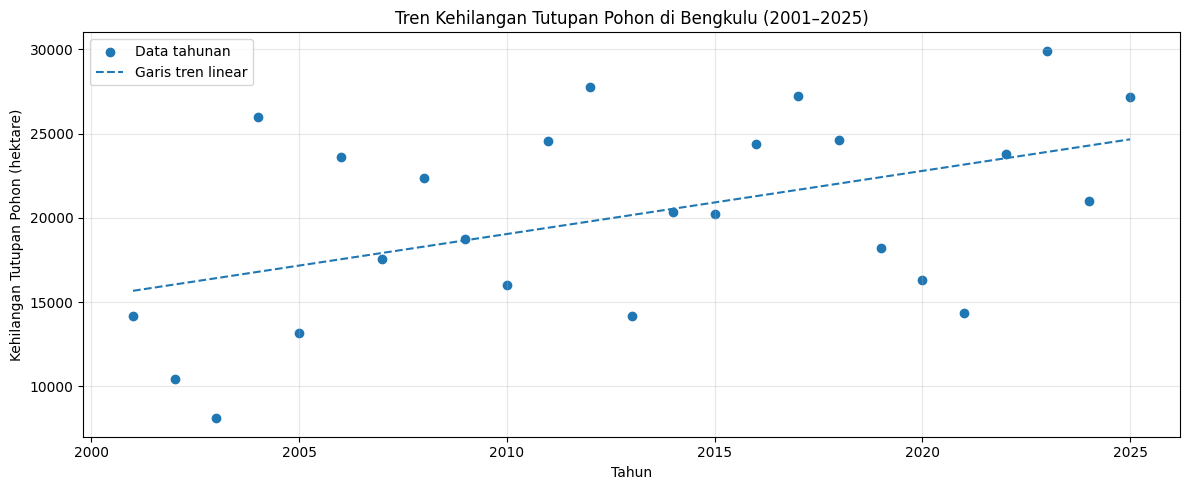

Kemiringan tren: 374.41 hektare per tahun
R-kuadrat: 0.224
Interpretasi: tren linear cenderung meningkat.


In [14]:

import numpy as np
import matplotlib.pyplot as plt

# Mengambil data yang valid
data_tren = tabel_bengkulu.dropna(
    subset=["Tahun", "Kehilangan_Tutupan_Pohon_ha"]
).copy()

x = data_tren["Tahun"].to_numpy()
y = data_tren["Kehilangan_Tutupan_Pohon_ha"].to_numpy()

# Menghitung garis tren linear
koefisien = np.polyfit(x, y, 1)
garis_tren = np.polyval(koefisien, x)

kemiringan = koefisien[0]

# Menghitung R-kuadrat
ss_res = np.sum((y - garis_tren) ** 2)
ss_tot = np.sum((y - np.mean(y)) ** 2)
r2 = 1 - (ss_res / ss_tot) if ss_tot != 0 else np.nan

# Membuat grafik
plt.figure(figsize=(12, 5))
plt.scatter(x, y, label="Data tahunan")
plt.plot(x, garis_tren, linestyle="--", label="Garis tren linear")

plt.title("Tren Kehilangan Tutupan Pohon di Bengkulu (2001–2025)")
plt.xlabel("Tahun")
plt.ylabel("Kehilangan Tutupan Pohon (hektare)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    "outputs/grafik_tren_bengkulu.png",
    dpi=300
)
plt.show()

print(f"Kemiringan tren: {kemiringan:,.2f} hektare per tahun")
print(f"R-kuadrat: {r2:.3f}")

if kemiringan > 0:
    print("Interpretasi: tren linear cenderung meningkat.")
elif kemiringan < 0:
    print("Interpretasi: tren linear cenderung menurun.")
else:
    print("Interpretasi: tidak ada kemiringan tren linear.")


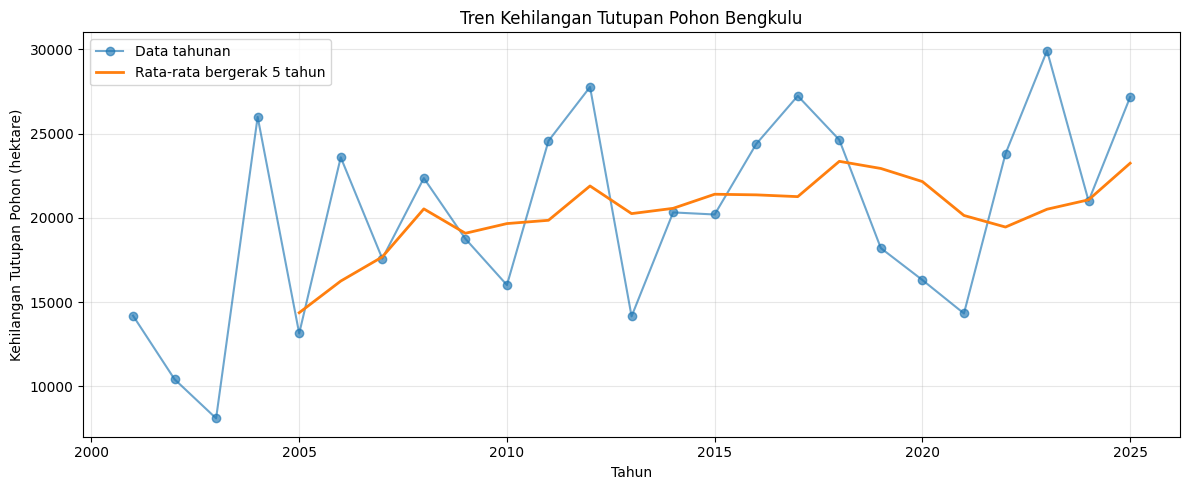

In [15]:

# Menghitung rata-rata bergerak 5 tahun
tabel_bengkulu["Rata_Rata_5_Tahun"] = (
    tabel_bengkulu["Kehilangan_Tutupan_Pohon_ha"]
    .rolling(window=5).mean()
)

plt.figure(figsize=(12, 5))

plt.plot(
    tabel_bengkulu["Tahun"],
    tabel_bengkulu["Kehilangan_Tutupan_Pohon_ha"],
    label="Data tahunan",
    alpha=0.65,
    marker="o"
)

plt.plot(
    tabel_bengkulu["Tahun"],
    tabel_bengkulu["Rata_Rata_5_Tahun"],
    label="Rata-rata bergerak 5 tahun",
    linewidth=2
)

plt.title("Tren Kehilangan Tutupan Pohon Bengkulu")
plt.xlabel("Tahun")
plt.ylabel("Kehilangan Tutupan Pohon (hektare)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    "outputs/grafik_moving_average_bengkulu.png",
    dpi=300
)

plt.show()


In [16]:

# Membandingkan rata-rata per periode lima tahunan
kolom = "Kehilangan_Tutupan_Pohon_ha"

periode = [
    (2001, 2005),
    (2006, 2010),
    (2011, 2015),
    (2016, 2020),
    (2021, 2025)
]

hasil_periode = []

for awal, akhir in periode:
    subset = tabel_bengkulu[
        tabel_bengkulu["Tahun"].between(awal, akhir)
    ]

    hasil_periode.append({
        "Periode": f"{awal}-{akhir}",
        "Rata-rata (ha/tahun)": subset[kolom].mean(),
        "Total (ha)": subset[kolom].sum()
    })

tabel_periode = pd.DataFrame(hasil_periode)

display(
    tabel_periode.round(2)
)

# Simpan hasil
tabel_periode.to_csv(
    "outputs/ringkasan_periode_5_tahun_bengkulu.csv",
    index=False
)

print("Ringkasan periode berhasil disimpan.")


,Periode,Rata-rata (ha/tahun),Total (ha)
0,2001-2005,14370.0,71850
1,2006-2010,19658.0,98290
2,2011-2015,21398.8,106994
3,2016-2020,22149.4,110747
4,2021-2025,23239.0,116195


Ringkasan periode berhasil disimpan.


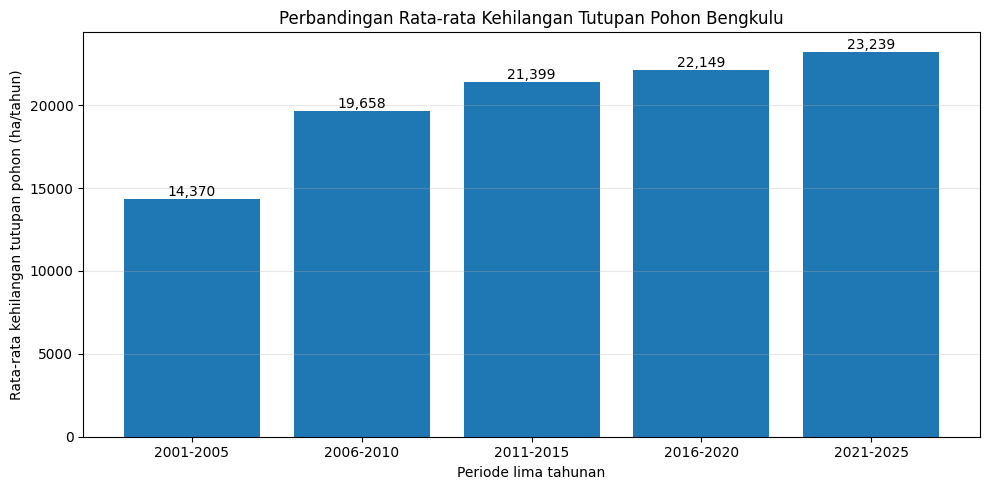

In [17]:

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

bars = plt.bar(
    tabel_periode["Periode"],
    tabel_periode["Rata-rata (ha/tahun)"]
)

plt.title(
    "Perbandingan Rata-rata Kehilangan Tutupan Pohon Bengkulu"
)
plt.xlabel("Periode lima tahunan")
plt.ylabel("Rata-rata kehilangan tutupan pohon (ha/tahun)")
plt.grid(axis="y", alpha=0.3)

# Menampilkan angka di atas setiap batang
for bar in bars:
    tinggi = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        tinggi,
        f"{tinggi:,.0f}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()

plt.savefig(
    "outputs/grafik_perbandingan_5_tahunan_bengkulu.png",
    dpi=300
)

plt.show()


In [18]:

tabel_periode["Perubahan_rata_rata_persen"] = (
    tabel_periode["Rata-rata (ha/tahun)"].pct_change() * 100
)

display(tabel_periode.round(2))


,Periode,Rata-rata (ha/tahun),Total (ha),Perubahan_rata_rata_persen
0,2001-2005,14370.0,71850,NaN
1,2006-2010,19658.0,98290,36.80
2,2011-2015,21398.8,106994,8.86
3,2016-2020,22149.4,110747,3.51
4,2021-2025,23239.0,116195,4.92


In [19]:

# Ringkasan akhir analisis Bengkulu

kolom = "Kehilangan_Tutupan_Pohon_ha"

# Tahun tertinggi dan terendah
data_valid = tabel_bengkulu.dropna(subset=[kolom])

tertinggi = data_valid.loc[data_valid[kolom].idxmax()]
terendah = data_valid.loc[data_valid[kolom].idxmin()]

# Periode dengan rata-rata tertinggi
periode_tertinggi = tabel_periode.loc[
    tabel_periode["Rata-rata (ha/tahun)"].idxmax()
]

# Perubahan rata-rata periode pertama ke terakhir
rata_awal = tabel_periode.iloc[0]["Rata-rata (ha/tahun)"]
rata_akhir = tabel_periode.iloc[-1]["Rata-rata (ha/tahun)"]

perubahan_persen = ((rata_akhir - rata_awal) / rata_awal) * 100

print("RINGKASAN ANALISIS BENGKULU")
print("=" * 40)

print(
    f"Tahun tertinggi: {int(tertinggi['Tahun'])} "
    f"({tertinggi[kolom]:,.0f} ha)"
)
print(
    f"Tahun terendah: {int(terendah['Tahun'])} "
    f"({terendah[kolom]:,.0f} ha)"
)
print(
    f"Periode rata-rata tertinggi: {periode_tertinggi['Periode']} "
    f"({periode_tertinggi['Rata-rata (ha/tahun)']:,.2f} ha/tahun)"
)
print(
    f"Perubahan rata-rata dari periode pertama ke terakhir: "
    f"{perubahan_persen:+.2f}%"
)


RINGKASAN ANALISIS BENGKULU
Tahun tertinggi: 2023 (29,913 ha)
Tahun terendah: 2003 (8,104 ha)
Periode rata-rata tertinggi: 2021-2025 (23,239.00 ha/tahun)
Perubahan rata-rata dari periode pertama ke terakhir: +61.72%


In [20]:

# Menyimpan hasil analisis dalam satu workbook Excel

with pd.ExcelWriter(
    "outputs/hasil_analisis_bengkulu.xlsx",
    engine="openpyxl"
) as writer:
    tabel_bengkulu.to_excel(
        writer, sheet_name="Data Tahunan", index=False
    )
    tabel_periode.to_excel(
        writer, sheet_name="Ringkasan Periode", index=False
    )

print("File Excel berhasil dibuat!")


File Excel berhasil dibuat!


In [21]:

from google.colab import files

files.download("outputs/hasil_analisis_bengkulu.xlsx")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [22]:

# Membuat draf hasil dan pembahasan otomatis

kolom = "Kehilangan_Tutupan_Pohon_ha"
data_valid = tabel_bengkulu.dropna(subset=[kolom])

tertinggi = data_valid.loc[data_valid[kolom].idxmax()]
terendah = data_valid.loc[data_valid[kolom].idxmin()]

rata_rata = data_valid[kolom].mean()

rata_awal = tabel_periode.iloc[0]["Rata-rata (ha/tahun)"]
rata_akhir = tabel_periode.iloc[-1]["Rata-rata (ha/tahun)"]

perubahan_persen = (rata_akhir - rata_awal) / rata_awal * 100

if perubahan_persen > 0:
    perbandingan = "meningkat"
elif perubahan_persen < 0:
    perbandingan = "menurun"
else:
    perbandingan = "tidak berubah"

draf = f"""
HASIL DAN PEMBAHASAN

Analisis dilakukan terhadap data kehilangan tutupan pohon
di Provinsi Bengkulu selama tahun 2001–2025, dengan
menggunakan indikator kehilangan tutupan pohon pada
ambang tutupan tajuk 30%.

Hasil pengolahan menunjukkan bahwa nilai kehilangan
tutupan pohon tertinggi terjadi pada tahun
{int(tertinggi['Tahun'])}, sebesar
{tertinggi[kolom]:,.0f} hektare. Nilai terendah terjadi
pada tahun {int(terendah['Tahun'])}, sebesar
{terendah[kolom]:,.0f} hektare.

Rata-rata kehilangan tutupan pohon selama periode
pengamatan adalah {rata_rata:,.2f} hektare per tahun.
Garis tren linear menunjukkan kecenderungan meningkat,
dengan kemiringan 374,41 hektare per tahun dan
R-kuadrat sebesar 0,224.

Perbandingan rata-rata lima tahunan menunjukkan bahwa
rata-rata periode terakhir {perbandingan} sebesar
{abs(perubahan_persen):.2f}% dibandingkan periode pertama.

Temuan ini menggambarkan adanya fluktuasi kehilangan
tutupan pohon selama periode pengamatan. Hasil ini
bersifat deskriptif dan belum menjelaskan penyebab
perubahan maupun membuktikan deforestasi permanen.

Catatan: kehilangan tutupan pohon tidak selalu identik
dengan kehilangan hutan alam atau deforestasi permanen.
"""

print(draf)

with open(
    "outputs/draf_hasil_pembahasan.txt",
    "w",
    encoding="utf-8"
) as file:
    file.write(draf)

print("\nDraf disimpan di outputs/draf_hasil_pembahasan.txt")



HASIL DAN PEMBAHASAN

Analisis dilakukan terhadap data kehilangan tutupan pohon
di Provinsi Bengkulu selama tahun 2001–2025, dengan
menggunakan indikator kehilangan tutupan pohon pada
ambang tutupan tajuk 30%.

Hasil pengolahan menunjukkan bahwa nilai kehilangan
tutupan pohon tertinggi terjadi pada tahun
2023, sebesar
29,913 hektare. Nilai terendah terjadi
pada tahun 2003, sebesar
8,104 hektare.

Rata-rata kehilangan tutupan pohon selama periode
pengamatan adalah 20,163.04 hektare per tahun.
Garis tren linear menunjukkan kecenderungan meningkat,
dengan kemiringan 374,41 hektare per tahun dan
R-kuadrat sebesar 0,224.

Perbandingan rata-rata lima tahunan menunjukkan bahwa
rata-rata periode terakhir meningkat sebesar
61.72% dibandingkan periode pertama.

Temuan ini menggambarkan adanya fluktuasi kehilangan
tutupan pohon selama periode pengamatan. Hasil ini
bersifat deskriptif dan belum menjelaskan penyebab
perubahan maupun membuktikan deforestasi permanen.

Catatan: kehilangan tutupan po

In [23]:

import os
import zipfile

folder_output = "outputs"

# Daftar hasil yang ingin dikumpulkan
file_hasil = [
    "data_kehilangan_tutupan_pohon_bengkulu.csv",
    "ringkasan_analisis_bengkulu.txt",
    "grafik_perubahan_tahunan_bengkulu.png",
    "grafik_tren_bengkulu.png",
    "grafik_moving_average_bengkulu.png",
    "grafik_perbandingan_5_tahunan_bengkulu.png",
    "hasil_analisis_bengkulu.xlsx",
    "draf_hasil_pembahasan.txt"
]

zip_path = "outputs/hasil_lengkap_analisis_bengkulu.zip"

with zipfile.ZipFile(zip_path, "w") as zipf:
    for nama in file_hasil:
        path = os.path.join(folder_output, nama)

        if os.path.exists(path):
            zipf.write(path, arcname=nama)
            print("Ditambahkan:", nama)
        else:
            print("Belum tersedia:", nama)

print("\nFile ZIP selesai dibuat.")


Ditambahkan: data_kehilangan_tutupan_pohon_bengkulu.csv
Ditambahkan: ringkasan_analisis_bengkulu.txt
Ditambahkan: grafik_perubahan_tahunan_bengkulu.png
Ditambahkan: grafik_tren_bengkulu.png
Ditambahkan: grafik_moving_average_bengkulu.png
Ditambahkan: grafik_perbandingan_5_tahunan_bengkulu.png
Ditambahkan: hasil_analisis_bengkulu.xlsx
Ditambahkan: draf_hasil_pembahasan.txt

File ZIP selesai dibuat.


In [24]:

from google.colab import files

files.download(
    "outputs/hasil_lengkap_analisis_bengkulu.zip"
)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [25]:

# VALIDASI KUALITAS DATA BENGKULU

kolom_tahun = "Tahun"
kolom_nilai = "Kehilangan_Tutupan_Pohon_ha"

print("VALIDASI DATA KEHILANGAN TUTUPAN POHON")
print("=" * 45)

# 1. Periksa jumlah baris
print("Jumlah baris data:", len(tabel_bengkulu))

# 2. Periksa rentang tahun
print(
    "Rentang tahun:",
    tabel_bengkulu[kolom_tahun].min(),
    "-",
    tabel_bengkulu[kolom_tahun].max()
)

# 3. Periksa tahun yang duplikat
duplikat = tabel_bengkulu[
    tabel_bengkulu[kolom_tahun].duplicated(keep=False)
]

print("Jumlah baris dengan tahun duplikat:", len(duplikat))

if not duplikat.empty:
    display(duplikat)

# 4. Periksa nilai kosong
print("\nNilai kosong:")
print(
    tabel_bengkulu[
        [kolom_tahun, kolom_nilai]
    ].isna().sum()
)

# 5. Periksa nilai negatif
jumlah_negatif = (
    tabel_bengkulu[kolom_nilai] < 0
).sum()

print("\nJumlah nilai kehilangan negatif:", jumlah_negatif)

# 6. Periksa apakah seluruh tahun 2001–2025 tersedia
tahun_diharapkan = set(range(2001, 2026))
tahun_tersedia = set(
    tabel_bengkulu[kolom_tahun].dropna().astype(int)
)

tahun_hilang = sorted(tahun_diharapkan - tahun_tersedia)

print("Tahun yang belum tersedia:", tahun_hilang)

if (
    len(tabel_bengkulu) == 25
    and duplikat.empty
    and tabel_bengkulu[kolom_nilai].notna().all()
    and jumlah_negatif == 0
    and not tahun_hilang
):
    print("\nPemeriksaan dasar berhasil.")
else:
    print("\nAda hal yang perlu diperiksa sebelum analisis dilanjutkan.")



VALIDASI DATA KEHILANGAN TUTUPAN POHON
Jumlah baris data: 25
Rentang tahun: 2001 - 2025
Jumlah baris dengan tahun duplikat: 0

Nilai kosong:
Tahun                          0
Kehilangan_Tutupan_Pohon_ha    0
dtype: int64

Jumlah nilai kehilangan negatif: 0
Tahun yang belum tersedia: []

Pemeriksaan dasar berhasil.


In [26]:

# Analisis kenaikan dan penurunan kehilangan tutupan pohon

tabel_analisis = tabel_bengkulu.copy()

tabel_analisis["Perubahan_ha"] = (
    tabel_analisis["Kehilangan_Tutupan_Pohon_ha"].diff()
)

tabel_analisis["Perubahan_persen"] = (
    tabel_analisis["Kehilangan_Tutupan_Pohon_ha"]
    .pct_change() * 100
)

# Tahun dengan kehilangan terbesar
tahun_tertinggi = tabel_analisis.loc[
    tabel_analisis["Kehilangan_Tutupan_Pohon_ha"].idxmax()
]

# Tahun dengan kenaikan tahunan terbesar
kenaikan_terbesar = tabel_analisis.loc[
    tabel_analisis["Perubahan_ha"].idxmax()
]

# Tahun dengan penurunan tahunan terbesar
penurunan_terbesar = tabel_analisis.loc[
    tabel_analisis["Perubahan_ha"].idxmin()
]

print("ANALISIS PERUBAHAN KEHILANGAN TUTUPAN POHON")
print("-" * 45)

print(
    f"Tahun kehilangan tertinggi: {int(tahun_tertinggi['Tahun'])}"
)
print(
    f"Luas kehilangan: "
    f"{tahun_tertinggi['Kehilangan_Tutupan_Pohon_ha']:,.0f} ha"
)

print(
    f"\nKenaikan tahunan terbesar: "
    f"{int(kenaikan_terbesar['Tahun'])}"
)
print(
    f"Perubahan: {kenaikan_terbesar['Perubahan_ha']:+,.0f} ha "
    f"({kenaikan_terbesar['Perubahan_persen']:+.2f}%)"
)

print(
    f"\nPenurunan tahunan terbesar: "
    f"{int(penurunan_terbesar['Tahun'])}"
)
print(
    f"Perubahan: {penurunan_terbesar['Perubahan_ha']:+,.0f} ha "
    f"({penurunan_terbesar['Perubahan_persen']:+.2f}%)"
)

display(tabel_analisis.tail(10))


ANALISIS PERUBAHAN KEHILANGAN TUTUPAN POHON
---------------------------------------------
Tahun kehilangan tertinggi: 2023
Luas kehilangan: 29,913 ha

Kenaikan tahunan terbesar: 2004
Perubahan: +17,881 ha (+220.64%)

Penurunan tahunan terbesar: 2013
Perubahan: -13,608 ha (-49.02%)


,Tahun,Kehilangan_Tutupan_Pohon_ha,Perubahan_ha,Perubahan_persen,Rata_Rata_5_Tahun
15,2016,24378,4181.0,20.701094,21361.8
16,2017,27233,2855.0,11.711379,21256.2
17,2018,24625,-2608.0,-9.576617,23350.6
18,2019,18201,-6424.0,-26.087310,22926.8
19,2020,16310,-1891.0,-10.389539,22149.4
20,2021,14326,-1984.0,-12.164316,20139.0
21,2022,23799,9473.0,66.124529,19452.2
22,2023,29913,6114.0,25.690155,20509.8
23,2024,20997,-8916.0,-29.806439,21069.0
24,2025,27160,6163.0,29.351812,23239.0


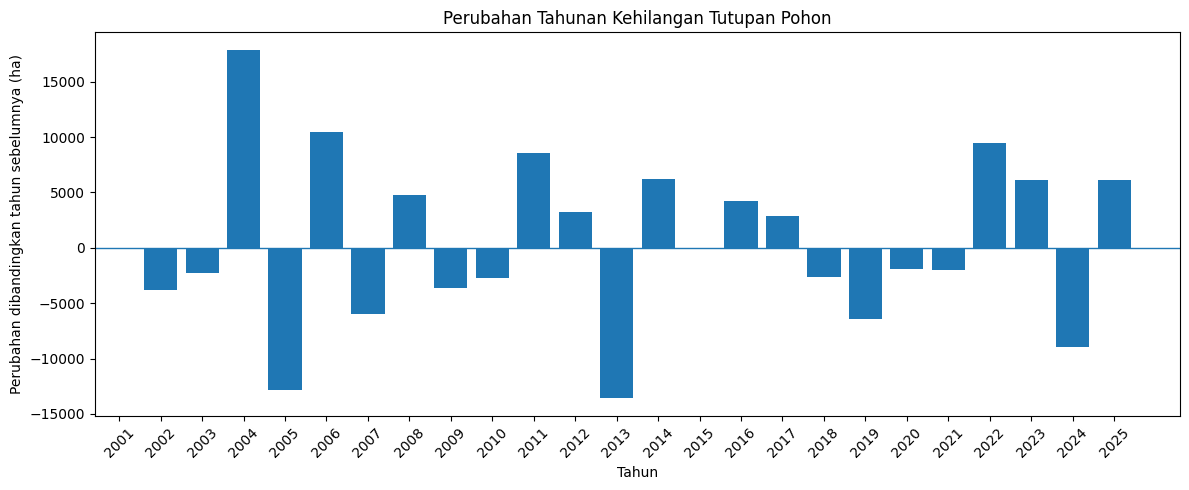

In [27]:

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.bar(
    tabel_analisis["Tahun"],
    tabel_analisis["Perubahan_ha"]
)

plt.axhline(y=0, linewidth=1)
plt.title("Perubahan Tahunan Kehilangan Tutupan Pohon")
plt.xlabel("Tahun")
plt.ylabel("Perubahan dibandingkan tahun sebelumnya (ha)")
plt.xticks(
    tabel_analisis["Tahun"],
    rotation=45
)
plt.tight_layout()

plt.savefig(
    "outputs/grafik_perubahan_tahunan.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [28]:

import os

os.makedirs("outputs", exist_ok=True)

# Simpan tabel analisis lengkap
tabel_analisis.to_csv(
    "outputs/analisis_perubahan_tahunan_bengkulu.csv",
    index=False
)

# Simpan ringkasan statistik
with open(
    "outputs/ringkasan_analisis_bengkulu.txt",
    "w",
    encoding="utf-8"
) as file:
    file.write("RINGKASAN ANALISIS KEHILANGAN TUTUPAN POHON\n")
    file.write("Periode: 2001–2025\n")
    file.write(
        f"Tahun kehilangan tertinggi: "
        f"{int(tahun_tertinggi['Tahun'])}\n"
    )
    file.write(
        f"Luas kehilangan tertinggi: "
        f"{tahun_tertinggi['Kehilangan_Tutupan_Pohon_ha']:,.0f} ha\n"
    )
    file.write(
        f"Tahun kenaikan terbesar: "
        f"{int(kenaikan_terbesar['Tahun'])}\n"
    )
    file.write(
        f"Kenaikan terbesar: "
        f"{kenaikan_terbesar['Perubahan_ha']:+,.0f} ha\n"
    )
    file.write(
        f"Tahun penurunan terbesar: "
        f"{int(penurunan_terbesar['Tahun'])}\n"
    )
    file.write(
        f"Penurunan terbesar: "
        f"{penurunan_terbesar['Perubahan_ha']:+,.0f} ha\n"
    )

print("File analisis berhasil disimpan!")
print("1. outputs/analisis_perubahan_tahunan_bengkulu.csv")
print("2. outputs/ringkasan_analisis_bengkulu.txt")


File analisis berhasil disimpan!
1. outputs/analisis_perubahan_tahunan_bengkulu.csv
2. outputs/ringkasan_analisis_bengkulu.txt


In [29]:

# Membuat tabel interpretasi hasil analisis

nilai_awal = tabel_bengkulu.iloc[0]
nilai_akhir = tabel_bengkulu.iloc[-1]

perubahan_total_persen = (
    (nilai_akhir["Kehilangan_Tutupan_Pohon_ha"]
     - nilai_awal["Kehilangan_Tutupan_Pohon_ha"])
    / nilai_awal["Kehilangan_Tutupan_Pohon_ha"]
) * 100

ringkasan = [
    {
        "Aspek": "Periode penelitian",
        "Hasil": "2001–2025",
        "Interpretasi": "Analisis mencakup 25 tahun pengamatan."
    },
    {
        "Aspek": "Kehilangan tertinggi",
        "Hasil": f"{int(tahun_tertinggi['Tahun'])}",
        "Interpretasi": (
            f"Kehilangan mencapai "
            f"{tahun_tertinggi['Kehilangan_Tutupan_Pohon_ha']:,.0f} ha."
        )
    },
    {
        "Aspek": "Kenaikan tahunan terbesar",
        "Hasil": f"{int(kenaikan_terbesar['Tahun'])}",
        "Interpretasi": (
            f"Naik sebesar "
            f"{kenaikan_terbesar['Perubahan_ha']:,.0f} ha "
            "dibandingkan tahun sebelumnya."
        )
    },
    {
        "Aspek": "Penurunan tahunan terbesar",
        "Hasil": f"{int(penurunan_terbesar['Tahun'])}",
        "Interpretasi": (
            f"Turun sebesar "
            f"{abs(penurunan_terbesar['Perubahan_ha']):,.0f} ha "
            "dibandingkan tahun sebelumnya."
        )
    },
    {
        "Aspek": "Perubahan 2001 ke 2025",
        "Hasil": f"{perubahan_total_persen:+.2f}%",
        "Interpretasi": (
            "Perbandingan nilai tahunan pada awal dan akhir periode, "
            "bukan perubahan total luas hutan."
        )
    }
]

tabel_ringkasan = pd.DataFrame(ringkasan)

display(tabel_ringkasan)

tabel_ringkasan.to_csv(
    "outputs/tabel_interpretasi_bengkulu.csv",
    index=False
)

print("Tabel interpretasi berhasil disimpan.")


,Aspek,Hasil,Interpretasi
0,Periode penelitian,2001–2025,Analisis mencakup 25 tahun pengamatan.
1,Kehilangan tertinggi,2023,"Kehilangan mencapai 29,913 ha."
2,Kenaikan tahunan terbesar,2004,"Naik sebesar 17,881 ha dibandingkan tahun sebe..."
3,Penurunan tahunan terbesar,2013,"Turun sebesar 13,608 ha dibandingkan tahun seb..."
4,Perubahan 2001 ke 2025,+91.29%,Perbandingan nilai tahunan pada awal dan akhir...


Tabel interpretasi berhasil disimpan.


In [30]:

# Membuat draf hasil dan pembahasan

os.makedirs("outputs", exist_ok=True)

tahun_awal = int(tabel_bengkulu.iloc[0]["Tahun"])
tahun_akhir = int(tabel_bengkulu.iloc[-1]["Tahun"])

luas_awal = tabel_bengkulu.iloc[0]["Kehilangan_Tutupan_Pohon_ha"]
luas_akhir = tabel_bengkulu.iloc[-1]["Kehilangan_Tutupan_Pohon_ha"]

draf = f"""
HASIL DAN PEMBAHASAN
Analisis Kehilangan Tutupan Pohon Periode {tahun_awal}–{tahun_akhir}

1. Gambaran Umum

Analisis dilakukan terhadap data kehilangan tutupan pohon
selama {tahun_akhir - tahun_awal + 1} tahun pengamatan,
yaitu dari tahun {tahun_awal} hingga {tahun_akhir}.
Analisis mencakup perubahan tahunan, rata-rata bergerak lima tahun,
serta perbandingan nilai kehilangan antarperiode.

2. Perubahan Tahunan

Berdasarkan data yang dianalisis, nilai kehilangan tutupan pohon
tertinggi terjadi pada tahun {int(tahun_tertinggi['Tahun'])},
yaitu sebesar {tahun_tertinggi['Kehilangan_Tutupan_Pohon_ha']:,.0f} ha.

Kenaikan tahunan terbesar terjadi pada tahun
{int(kenaikan_terbesar['Tahun'])}, dengan kenaikan sebesar
{kenaikan_terbesar['Perubahan_ha']:,.0f} ha dibandingkan tahun sebelumnya.

Sementara itu, penurunan tahunan terbesar terjadi pada tahun
{int(penurunan_terbesar['Tahun'])}, sebesar
{abs(penurunan_terbesar['Perubahan_ha']):,.0f} ha dibandingkan tahun sebelumnya.

3. Perbandingan Awal dan Akhir Periode

Pada tahun {tahun_awal}, nilai kehilangan tutupan pohon tercatat
sebesar {luas_awal:,.0f} ha, sedangkan pada tahun {tahun_akhir}
sebesar {luas_akhir:,.0f} ha. Perbandingan kedua nilai tersebut
menunjukkan perubahan sebesar {perubahan_total_persen:+.2f}%.

Persentase tersebut merupakan perubahan nilai kehilangan tahunan
antara dua tahun pengamatan, bukan persentase total luas hutan
yang hilang selama keseluruhan periode.

4. Catatan Interpretasi

Data menunjukkan adanya fluktuasi kehilangan tutupan pohon
dari tahun ke tahun. Hasil ini belum cukup untuk menetapkan
penyebab perubahan atau menyimpulkan terjadinya deforestasi permanen.
Interpretasi akhir perlu mempertimbangkan sumber data, cakupan wilayah,
definisi kehilangan tutupan pohon, serta metode pengukuran yang digunakan.
"""

with open(
    "outputs/draf_hasil_pembahasan.txt",
    "w",
    encoding="utf-8"
) as file:
    file.write(draf)

print(draf)
print("\nDraf berhasil disimpan di outputs/draf_hasil_pembahasan.txt")



HASIL DAN PEMBAHASAN
Analisis Kehilangan Tutupan Pohon Periode 2001–2025

1. Gambaran Umum

Analisis dilakukan terhadap data kehilangan tutupan pohon
selama 25 tahun pengamatan,
yaitu dari tahun 2001 hingga 2025.
Analisis mencakup perubahan tahunan, rata-rata bergerak lima tahun,
serta perbandingan nilai kehilangan antarperiode.

2. Perubahan Tahunan

Berdasarkan data yang dianalisis, nilai kehilangan tutupan pohon
tertinggi terjadi pada tahun 2023,
yaitu sebesar 29,913 ha.

Kenaikan tahunan terbesar terjadi pada tahun
2004, dengan kenaikan sebesar
17,881 ha dibandingkan tahun sebelumnya.

Sementara itu, penurunan tahunan terbesar terjadi pada tahun
2013, sebesar
13,608 ha dibandingkan tahun sebelumnya.

3. Perbandingan Awal dan Akhir Periode

Pada tahun 2001, nilai kehilangan tutupan pohon tercatat
sebesar 14,198 ha, sedangkan pada tahun 2025
sebesar 27,160 ha. Perbandingan kedua nilai tersebut
menunjukkan perubahan sebesar +91.29%.

Persentase tersebut merupakan perubahan nilai kehi

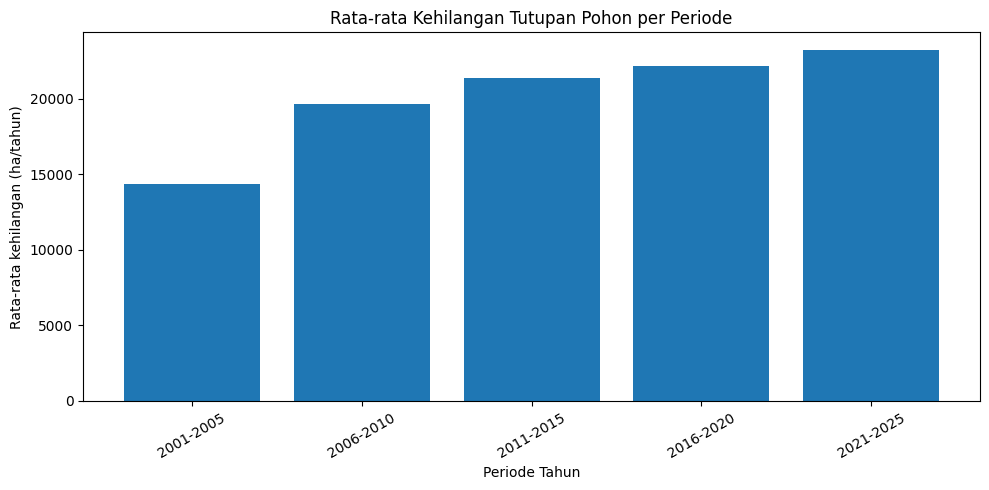

,Periode,Kehilangan_Tutupan_Pohon_ha,Rentang_Tahun
0,2001,14370.0,2001-2005
1,2006,19658.0,2006-2010
2,2011,21398.8,2011-2015
3,2016,22149.4,2016-2020
4,2021,23239.0,2021-2025


In [31]:

import matplotlib.pyplot as plt
import os

os.makedirs("outputs", exist_ok=True)

# Menghitung rata-rata kehilangan untuk setiap periode 5 tahun
tabel_periode = tabel_bengkulu.copy()

tabel_periode["Periode"] = (
    (tabel_periode["Tahun"] - 2001) // 5
) * 5 + 2001

ringkasan_periode = (
    tabel_periode.groupby("Periode")
    ["Kehilangan_Tutupan_Pohon_ha"]
    .mean()
    .reset_index()
)

ringkasan_periode["Rentang_Tahun"] = (
    ringkasan_periode["Periode"].astype(str)
    + "-"
    + (ringkasan_periode["Periode"] + 4)
    .clip(upper=2025).astype(str)
)

plt.figure(figsize=(10, 5))

plt.bar(
    ringkasan_periode["Rentang_Tahun"],
    ringkasan_periode["Kehilangan_Tutupan_Pohon_ha"]
)

plt.title("Rata-rata Kehilangan Tutupan Pohon per Periode")
plt.xlabel("Periode Tahun")
plt.ylabel("Rata-rata kehilangan (ha/tahun)")
plt.xticks(rotation=30)
plt.tight_layout()

plt.savefig(
    "outputs/grafik_rata_rata_periode.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

display(ringkasan_periode)


In [32]:

# Simpan ringkasan periode lima tahunan

ringkasan_periode.to_csv(
    "outputs/ringkasan_kehilangan_periode_5_tahun.csv",
    index=False
)

print("Tabel periode berhasil disimpan!")
print("Lokasi: outputs/ringkasan_kehilangan_periode_5_tahun.csv")


Tabel periode berhasil disimpan!
Lokasi: outputs/ringkasan_kehilangan_periode_5_tahun.csv


In [33]:
import os
import glob
import pandas as pd

print("=== 1. STATUS NOTEBOOK ===")
print("Variabel analisis yang masih tersedia:")

nama_variabel = [
    "tabel_bengkulu",
    "tabel_analisis",
    "tabel_periode"
]

for nama in nama_variabel:
    if nama in globals():
        objek = globals()[nama]
        print(f"\n{nama}: tersedia")
        if isinstance(objek, pd.DataFrame):
            print("Ukuran:", objek.shape)
            print("Kolom:", list(objek.columns))
    else:
        print(f"{nama}: tidak tersedia")

print("\n=== 2. FILE HASIL YANG DITEMUKAN ===")

pola_file = [
    "/content/**/*.png",
    "/content/**/*.csv",
    "/content/**/*.txt",
    "/content/**/*.ipynb"
]

file_ditemukan = []

for pola in pola_file:
    file_ditemukan.extend(
        glob.glob(pola, recursive=True)
    )

if file_ditemukan:
    for file in sorted(set(file_ditemukan)):
        print(file)
else:
    print("Tidak ditemukan file hasil di /content.")

print("\n=== 3. FOLDER OUTPUTS ===")
print("Folder outputs tersedia:",
      os.path.isdir("/content/outputs"))

=== 1. STATUS NOTEBOOK ===
Variabel analisis yang masih tersedia:

tabel_bengkulu: tersedia
Ukuran: (25, 5)
Kolom: ['Tahun', 'Kehilangan_Tutupan_Pohon_ha', 'Perubahan_ha', 'Perubahan_persen', 'Rata_Rata_5_Tahun']

tabel_analisis: tersedia
Ukuran: (25, 5)
Kolom: ['Tahun', 'Kehilangan_Tutupan_Pohon_ha', 'Perubahan_ha', 'Perubahan_persen', 'Rata_Rata_5_Tahun']

tabel_periode: tersedia
Ukuran: (25, 6)
Kolom: ['Tahun', 'Kehilangan_Tutupan_Pohon_ha', 'Perubahan_ha', 'Perubahan_persen', 'Rata_Rata_5_Tahun', 'Periode']

=== 2. FILE HASIL YANG DITEMUKAN ===
/content/outputs/analisis_perubahan_tahunan_bengkulu.csv
/content/outputs/data_kehilangan_tutupan_pohon_bengkulu.csv
/content/outputs/draf_hasil_pembahasan.txt
/content/outputs/grafik_kehilangan_tutupan_pohon_bengkulu.png
/content/outputs/grafik_moving_average_bengkulu.png
/content/outputs/grafik_perbandingan_5_tahunan_bengkulu.png
/content/outputs/grafik_perubahan_tahunan.png
/content/outputs/grafik_perubahan_tahunan_bengkulu.png
/content/o

In [34]:
from google.colab import drive
import os
import shutil

# Hubungkan Google Drive
drive.mount('/content/drive')

# Lokasi hasil analisis yang sudah ada di Colab
folder_asal = '/content/outputs'

# Folder proyek di Google Drive
folder_proyek = (
    '/content/drive/MyDrive/'
    'analisis-kehilangan-tutupan-pohon-bengkulu'
)
folder_tujuan = os.path.join(folder_proyek, 'outputs')

# Pastikan folder tujuan tersedia
os.makedirs(folder_tujuan, exist_ok=True)

# Salin semua file hasil analisis yang tersedia
jumlah_file = 0

for nama_file in os.listdir(folder_asal):
    path_asal = os.path.join(folder_asal, nama_file)
    path_tujuan = os.path.join(folder_tujuan, nama_file)

    if os.path.isfile(path_asal):
        shutil.copy2(path_asal, path_tujuan)
        print('Tersalin:', nama_file)
        jumlah_file += 1

print(f'\nSelesai! {jumlah_file} file disalin.')
print('Lokasi Google Drive:', folder_tujuan)

Mounted at /content/drive
Tersalin: data_kehilangan_tutupan_pohon_bengkulu.csv
Tersalin: ringkasan_analisis_bengkulu.txt
Tersalin: grafik_rata_rata_periode.png
Tersalin: grafik_kehilangan_tutupan_pohon_bengkulu.png
Tersalin: grafik_perubahan_tahunan.png
Tersalin: ringkasan_periode_5_tahun_bengkulu.csv
Tersalin: draf_hasil_pembahasan.txt
Tersalin: hasil_analisis_bengkulu.xlsx
Tersalin: grafik_perubahan_tahunan_bengkulu.png
Tersalin: grafik_moving_average_bengkulu.png
Tersalin: analisis_perubahan_tahunan_bengkulu.csv
Tersalin: grafik_tren_bengkulu.png
Tersalin: hasil_lengkap_analisis_bengkulu.zip
Tersalin: grafik_perbandingan_5_tahunan_bengkulu.png
Tersalin: ringkasan_kehilangan_periode_5_tahun.csv
Tersalin: tabel_interpretasi_bengkulu.csv

Selesai! 16 file disalin.
Lokasi Google Drive: /content/drive/MyDrive/analisis-kehilangan-tutupan-pohon-bengkulu/outputs
